# Redes Neurais Artificiais para Previsão de Churn Bancário
**Atividade Prática de Redes Neurais (MLP)**  
**Objetivo:** Construir e avaliar uma Rede Neural Artificial (Multilayer Perceptron - MLP) em PyTorch para prever quais clientes de um banco europeu irão encerrar o relacionamento (*churn*), comparando os resultados com um modelo de referência (Regressão Logística) e extraindo insights de negócio.

---
### Estrutura do Notebook:
1. **Análise Exploratória de Dados (EDA)**
2. **Pré-processamento e Divisão dos Dados**
3. **Modelo de Referência (Baseline) e Primeira Rede Neural**
4. **Ajuste de Hiperparâmetros e Regularização**
5. **Tratamento de Desbalanceamento e Avaliação Final**
6. **Interpretação e Recomendações de Negócio**
7. **Questões Teóricas**


## 0. Importação das Bibliotecas e Fixação de Sementes Aleatórias
Para assegurar a reprodutibilidade estrita de todos os experimentos, fixamos as sementes aleatórias do `random`, `numpy` e `torch`, além de definir `random_state=42` nas divisões dos dados.


In [1]:
import random
import os
import copy
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import TensorDataset, DataLoader

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder, OrdinalEncoder
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, roc_curve, precision_recall_curve,
    confusion_matrix, ConfusionMatrixDisplay, classification_report
)
from sklearn.inspection import permutation_importance
from imblearn.over_sampling import SMOTE

# Estilo visual dos gráficos
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams["figure.figsize"] = (8, 5)
plt.rcParams["font.size"] = 11

# Fixação rigorosa de sementes aleatórias para reprodutibilidade
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

print("Ambiente configurado com sucesso! Sementes fixadas em:", SEED)


Ambiente configurado com sucesso! Sementes fixadas em: 42


---
## Parte 1: Análise Exploratória de Dados (EDA)

Nesta etapa, investigamos a estrutura da base de dados `Churn_Modelling.csv`:
- Verificação de dimensões, tipos de atributos, valores nulos e duplicados.
- Análise da proporção da variável-alvo `Exited`.
- Análise bivariada da taxa de churn por atributos categóricos e comportamentais.
- Comparação das distribuições numéricas entre clientes que saíram e permaneceram.
- Formulação de 3 hipóteses de negócio fundamentadas nos dados.


In [2]:
# 1.1 Carregamento da base e inspeção geral
df = pd.read_csv('Churn_Modelling.csv')

print(f"Dimensões da base: {df.shape[0]} linhas e {df.shape[1]} colunas.")
print(f"Valores nulos/ausentes: {df.isnull().sum().sum()}")
print(f"Linhas duplicadas: {df.duplicated().sum()}")
print("\nPrimeiras 5 linhas do dataset:")
display(df.head())

print("\nTipos de dados e informações do dataset:")
df.info()


Dimensões da base: 10000 linhas e 14 colunas.
Valores nulos/ausentes: 0
Linhas duplicadas: 0

Primeiras 5 linhas do dataset:


,RowNumber,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,1,15634602,Hargrave,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,2,15647311,Hill,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,3,15619304,Onio,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,4,15701354,Boni,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,5,15737888,Mitchell,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0



Tipos de dados e informações do dataset:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   RowNumber        10000 non-null  int64  
 1   CustomerId       10000 non-null  int64  
 2   Surname          10000 non-null  object 
 3   CreditScore      10000 non-null  int64  
 4   Geography        10000 non-null  object 
 5   Gender           10000 non-null  object 
 6   Age              10000 non-null  int64  
 7   Tenure           10000 non-null  int64  
 8   Balance          10000 non-null  float64
 9   NumOfProducts    10000 non-null  int64  
 10  HasCrCard        10000 non-null  int64  
 11  IsActiveMember   10000 non-null  int64  
 12  EstimatedSalary  10000 non-null  float64
 13  Exited           10000 non-null  int64  
dtypes: float64(2), int64(9), object(3)
memory usage: 1.1+ MB


### 1.2 Proporção de Churn
Avaliamos a distribuição da variável-alvo `Exited` ($0 = \text{permaneceu}$, $1 = \text{saiu do banco}$).


Distribuição da variável-alvo (Exited):


,Total,Percentual (%)
Permaneceu (0),7963,79.63
Saiu (1),2037,20.37


C:\Users\poxaj\AppData\Local\Temp\ipykernel_3380\2078081070.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=churn_counts.index, y=churn_counts.values, ax=axes[0], palette=['#4C72B0', '#C44E52'])


C:\Users\poxaj\AppData\Local\Temp\ipykernel_3380\2078081070.py:16: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  axes[0].set_xticklabels(['Permaneceu (0)', 'Saiu (1)'])


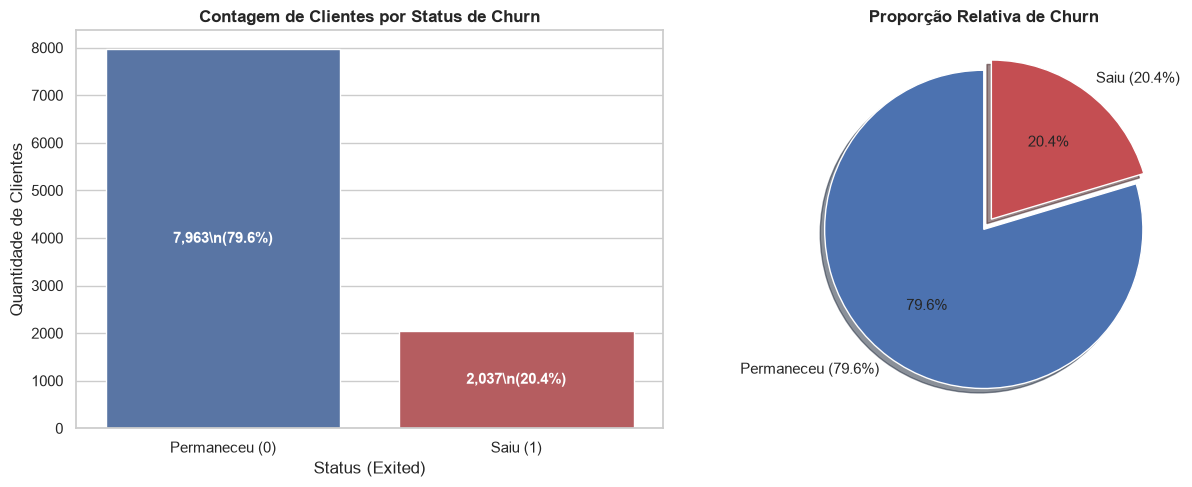

A taxa exata de churn na base é de 20.37%. A classe positiva (1) é nitidamente minoritária.


In [3]:
churn_counts = df['Exited'].value_counts()
churn_pct = df['Exited'].value_counts(normalize=True) * 100

summary_churn = pd.DataFrame({'Total': churn_counts, 'Percentual (%)': churn_pct.round(2)})
summary_churn.index = ['Permaneceu (0)', 'Saiu (1)']
print("Distribuição da variável-alvo (Exited):")
display(summary_churn)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Gráfico de Barras
sns.barplot(x=churn_counts.index, y=churn_counts.values, ax=axes[0], palette=['#4C72B0', '#C44E52'])
axes[0].set_title('Contagem de Clientes por Status de Churn', fontweight='bold')
axes[0].set_xlabel('Status (Exited)')
axes[0].set_ylabel('Quantidade de Clientes')
axes[0].set_xticklabels(['Permaneceu (0)', 'Saiu (1)'])
for p in axes[0].patches:
    axes[0].annotate(f"{int(p.get_height()):,}\\n({p.get_height()/len(df)*100:.1f}%)", 
                     (p.get_x() + p.get_width() / 2., p.get_height() / 2),
                     ha='center', va='center', color='white', fontweight='bold')

# Gráfico de Pizza
axes[1].pie(churn_counts.values, labels=['Permaneceu (79.6%)', 'Saiu (20.4%)'], 
            autopct='%1.1f%%', startangle=90, colors=['#4C72B0', '#C44E52'],
            explode=(0, 0.08), shadow=True)
axes[1].set_title('Proporção Relativa de Churn', fontweight='bold')

plt.tight_layout()
plt.show()

print(f"A taxa exata de churn na base é de {churn_pct[1]:.2f}%. A classe positiva (1) é nitidamente minoritária.")


### 1.3 Taxa de Churn por Atributos Selecionados
Comparamos a taxa média de evasão por `Geography`, `Gender`, `IsActiveMember` e `NumOfProducts`.


C:\Users\poxaj\AppData\Local\Temp\ipykernel_3380\3949501832.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=taxa, x=col, y='taxa_pct', ax=axes[i], palette='viridis')
C:\Users\poxaj\AppData\Local\Temp\ipykernel_3380\3949501832.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=taxa, x=col, y='taxa_pct', ax=axes[i], palette='viridis')
C:\Users\poxaj\AppData\Local\Temp\ipykernel_3380\3949501832.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=taxa, x=col, y='taxa_pct', ax=axes[i], palette='viridis')
C:\Users\poxaj\AppData

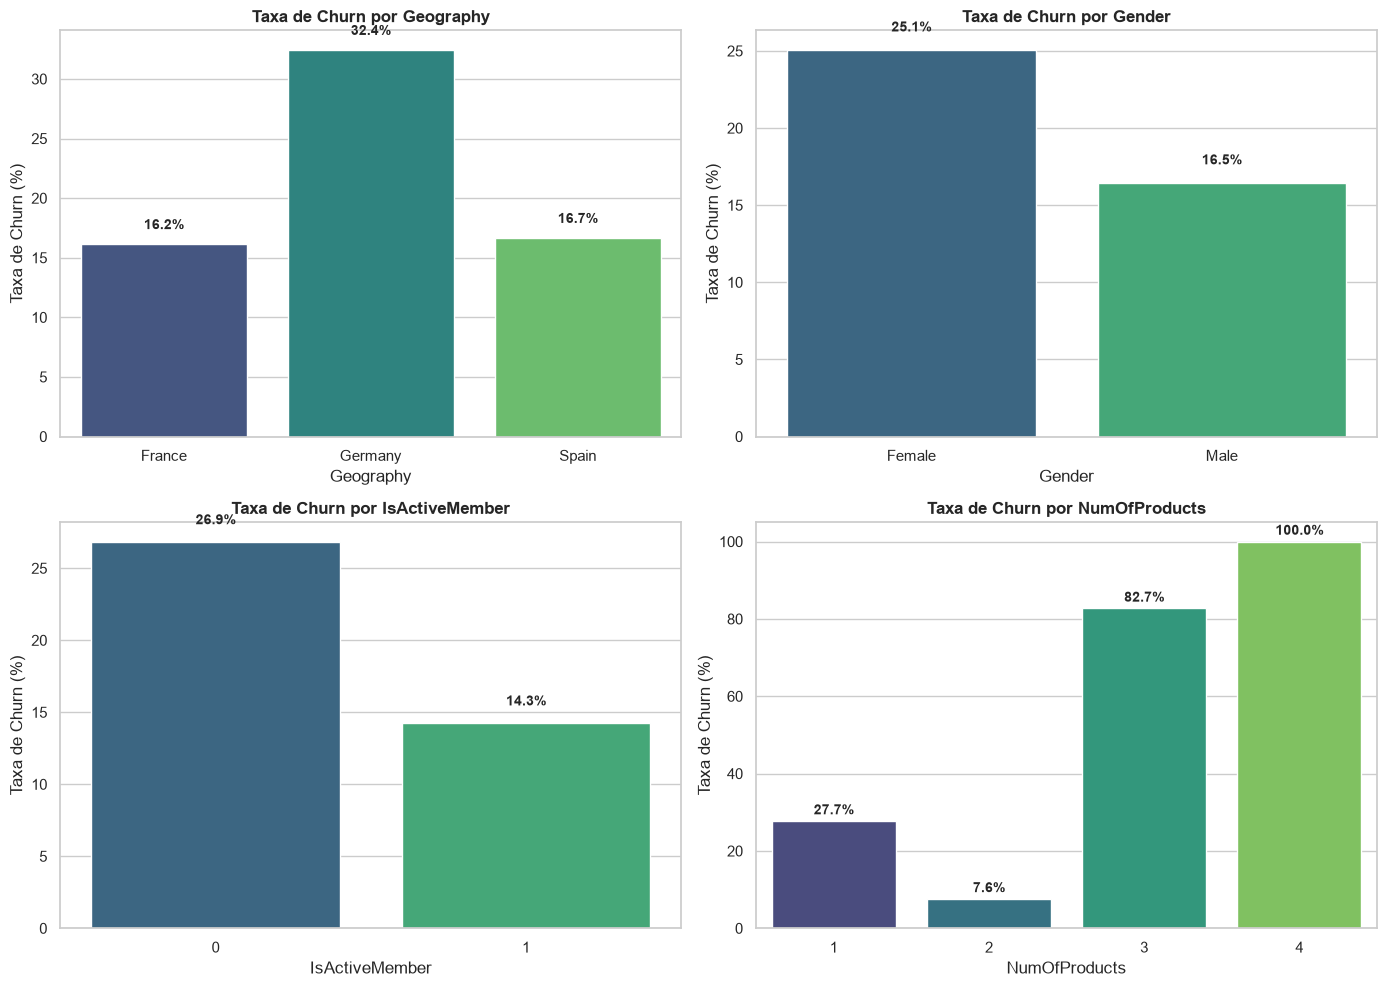

--- Tabela: Churn por Geography ---


,Total,Churns,Taxa_Churn
Geography,,,
France,5014,810,16.15%
Germany,2509,814,32.44%
Spain,2477,413,16.67%


--- Tabela: Churn por Gender ---


,Total,Churns,Taxa_Churn
Gender,,,
Female,4543,1139,25.07%
Male,5457,898,16.46%


--- Tabela: Churn por IsActiveMember ---


,Total,Churns,Taxa_Churn
IsActiveMember,,,
0,4849,1302,26.85%
1,5151,735,14.27%


--- Tabela: Churn por NumOfProducts ---


,Total,Churns,Taxa_Churn
NumOfProducts,,,
1,5084,1409,27.71%
2,4590,348,7.58%
3,266,220,82.71%
4,60,60,100.00%


In [4]:
features_to_compare = ['Geography', 'Gender', 'IsActiveMember', 'NumOfProducts']
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
axes = axes.flatten()

for i, col in enumerate(features_to_compare):
    taxa = df.groupby(col)['Exited'].agg(['count', 'mean']).reset_index()
    taxa['taxa_pct'] = taxa['mean'] * 100
    
    sns.barplot(data=taxa, x=col, y='taxa_pct', ax=axes[i], palette='viridis')
    axes[i].set_title(f'Taxa de Churn por {col}', fontweight='bold')
    axes[i].set_ylabel('Taxa de Churn (%)')
    axes[i].set_xlabel(col)
    
    for p in axes[i].patches:
        h = p.get_height()
        axes[i].annotate(f"{h:.1f}%", (p.get_x() + p.get_width() / 2., h + 1),
                         ha='center', va='bottom', fontweight='bold', fontsize=10)

plt.tight_layout()
plt.show()

# Tabela resumo das taxas
for col in features_to_compare:
    t = df.groupby(col)['Exited'].agg(Total='count', Churns='sum', Taxa_Churn=lambda x: f"{x.mean()*100:.2f}%")
    print(f"--- Tabela: Churn por {col} ---")
    display(t)


### 1.4 Distribuições Numéricas por Classe (`Age`, `Balance`, `CreditScore`)
Avaliamos as diferenças distributivas entre clientes que saíram (`Exited=1`) e permaneceram (`Exited=0`).


C:\Users\poxaj\AppData\Local\Temp\ipykernel_3380\313434832.py:13: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='Exited', y=var, palette=['#4C72B0', '#C44E52'], ax=axes[i, 1])
C:\Users\poxaj\AppData\Local\Temp\ipykernel_3380\313434832.py:15: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  axes[i, 1].set_xticklabels(['Permaneceu (0)', 'Saiu (1)'])
C:\Users\poxaj\AppData\Local\Temp\ipykernel_3380\313434832.py:13: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='Exited', y=var, palette=['#4C72B0', '#C44E52'], ax=axes[i, 1])
C:\Users\poxaj\AppData\Local\Temp

C:\Users\poxaj\AppData\Local\Temp\ipykernel_3380\313434832.py:13: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='Exited', y=var, palette=['#4C72B0', '#C44E52'], ax=axes[i, 1])
C:\Users\poxaj\AppData\Local\Temp\ipykernel_3380\313434832.py:15: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  axes[i, 1].set_xticklabels(['Permaneceu (0)', 'Saiu (1)'])


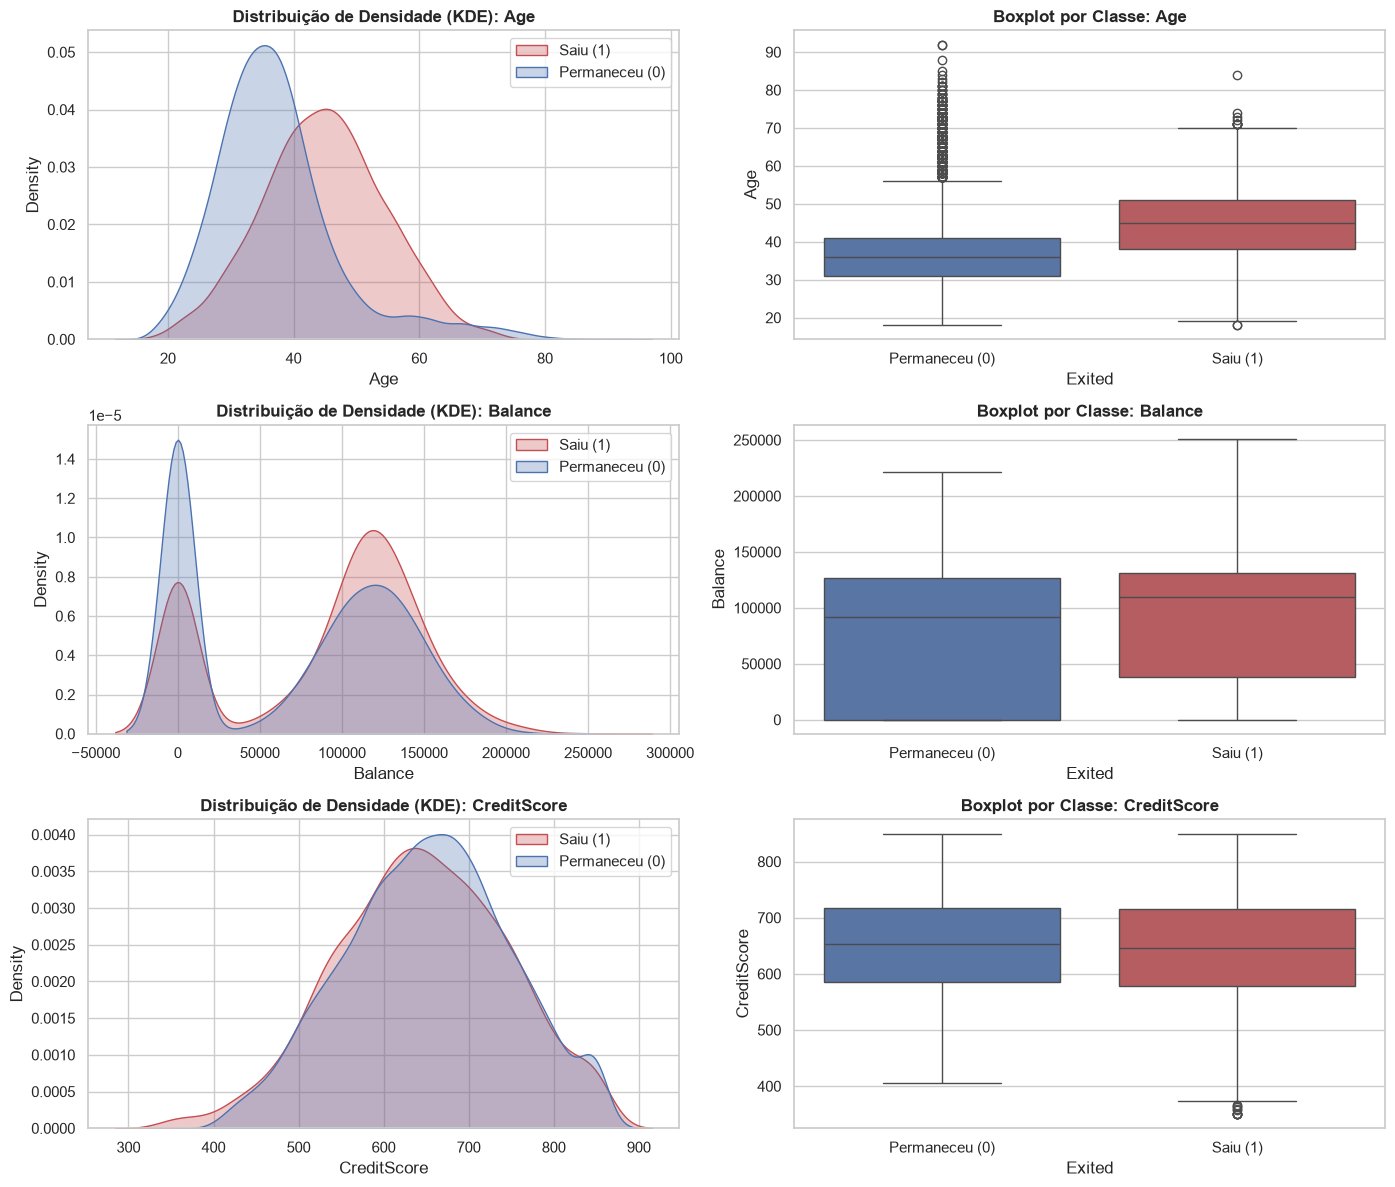

Estatísticas de Age separadas por classe:


,count,mean,std,min,25%,50%,75%,max
Exited,,,,,,,,
0,7963.0,37.41,10.13,18.0,31.0,36.0,41.0,92.0
1,2037.0,44.84,9.76,18.0,38.0,45.0,51.0,84.0


Estatísticas de Balance separadas por classe:


,count,mean,std,min,25%,50%,75%,max
Exited,,,,,,,,
0,7963.0,72745.30,62848.04,0.0,0.00,92072.68,126410.28,221532.80
1,2037.0,91108.54,58360.79,0.0,38340.02,109349.29,131433.33,250898.09


Estatísticas de CreditScore separadas por classe:


,count,mean,std,min,25%,50%,75%,max
Exited,,,,,,,,
0,7963.0,651.85,95.65,405.0,585.0,653.0,718.0,850.0
1,2037.0,645.35,100.32,350.0,578.0,646.0,716.0,850.0


In [5]:
fig, axes = plt.subplots(3, 2, figsize=(14, 12))

num_vars = ['Age', 'Balance', 'CreditScore']

for i, var in enumerate(num_vars):
    # KDE Plot
    sns.kdeplot(data=df, x=var, hue='Exited', common_norm=False, fill=True, 
                palette=['#4C72B0', '#C44E52'], alpha=0.3, ax=axes[i, 0])
    axes[i, 0].set_title(f'Distribuição de Densidade (KDE): {var}', fontweight='bold')
    axes[i, 0].legend(['Saiu (1)', 'Permaneceu (0)'])
    
    # Boxplot
    sns.boxplot(data=df, x='Exited', y=var, palette=['#4C72B0', '#C44E52'], ax=axes[i, 1])
    axes[i, 1].set_title(f'Boxplot por Classe: {var}', fontweight='bold')
    axes[i, 1].set_xticklabels(['Permaneceu (0)', 'Saiu (1)'])

plt.tight_layout()
plt.show()

# Estatísticas descritivas por classe
for var in num_vars:
    print(f"Estatísticas de {var} separadas por classe:")
    display(df.groupby('Exited')[var].describe().round(2))


### 1.5 Formulação de Três Hipóteses de Negócio

Com base na exploração dos dados, formulamos três hipóteses centrais sobre os fatores determinantes do churn:

1. **Hipótese 1 (Fator Idade):** *Clientes mais velhos possuem propensão acentuadamente maior ao churn.*  
   *Evidência:* A idade média dos clientes que saíram é de **44,8 anos** (mediana 45), em comparação a **37,4 anos** (mediana 36) dos que permaneceram. O gráfico de densidade revela uma concentração expressiva de evasão na faixa dos 40 aos 60 anos, sugerindo migração para instituições com produtos patrimoniais ou de aposentadoria mais atraentes.

2. **Hipótese 2 (Número de Produtos e Relação com o Banco):** *O volume de produtos contratados possui relação não linear crítica com o churn.*  
   *Evidência:* Clientes com 2 produtos possuem a menor taxa de churn de toda a base (**7,58%**). Em contraste, clientes com apenas 1 produto evadem em **27,71%** dos casos (baixo vínculo), enquanto clientes com 3 produtos sofrem churn alarmante de **82,71%** e clientes com 4 produtos têm **100% de churn** (todos os 60 clientes saíram, indicando atrito por má experiência ou sobrecarga comercial).

3. **Hipótese 3 (Geografia e Saldo em Conta na Alemanha):** *Clientes alemães de maior patrimônio têm risco dobrado de encerramento de conta.*  
   *Evidência:* A taxa de churn na Alemanha é de **32,44%**, exatamente o dobro da observada na França (16,15%) e Espanha (16,67%). Somado a isso, o saldo médio dos clientes que saíram é substancialmente maior (~91 mil vs ~72 mil), apontando para a perda de clientes de alto valor na operação alemã para bancos concorrentes locais.


---
## Parte 2: Pré-processamento e Pipeline de Transformação

Nesta etapa:
1. Removemos identificadores sem valor preditivo.
2. Codificamos atributos categóricos e justificamos as técnicas escolhidas.
3. Realizamos a divisão estratificada em Treino (70%), Validação (15%) e Teste (15%).
4. Padronizamos os dados com `StandardScaler` ajustado estritamente no treino.
5. Construímos um `ColumnTransformer` consolidado para garantir blindagem contra vazamento de dados (*data leakage*).


### 2.1 Remoção de Atributos Irrelevantes
- **Atributos removidos:** `RowNumber`, `CustomerId`, `Surname`.
- **Justificativa:** 
  - `RowNumber` é apenas o índice sequencial da linha (1 a 10.000).
  - `CustomerId` é uma chave primária numérica arbitrária gerada pelo sistema transacional do banco.
  - `Surname` é o sobrenome textual do cliente com alta cardinalidade.  
  Nenhum desses campos possui valor causal ou preditivo generalizável sobre o comportamento financeiro. Mantê-los injetaria ruído espúrio e permitiria que a rede neural decorasse amostras específicas (*memorization/overfitting*), além de violar princípios de privacidade (LGPD/GDPR).


### 2.2 Codificação de Variáveis Categóricas e Justificativa Teórica
- **`Gender` (Gênero):** Codificação binária ($0 = \text{Female}, 1 = \text{Male}$), já que a variável possui apenas duas categorias mutuamente excludentes.
- **`Geography` (País):** Codificação One-Hot gerando 3 colunas indicadoras binárias (`Geography_France`, `Geography_Germany`, `Geography_Spain`).
- **Por que NÃO usar codificação ordinal em `Geography`?**  
  A codificação ordinal atribui números inteiros arbitrários a categorias sem ordem natural (por exemplo: França = 0, Alemanha = 1, Espanha = 2). Em modelos lineares e redes neurais, as entradas são multiplicadas por matrizes de pesos ($z = \mathbf{w}^T \mathbf{x} + b$). O uso de ordinal forçaria uma relação geométrica e métrica inexistente: implicaria que Espanha ($2$) é o dobro da Alemanha ($1$), e que a Alemanha está equidistantemente posicionada entre a França e a Espanha. Isso distorceria os gradientes e a capacidade de aproximação da rede. A codificação One-Hot resolve isso ao projetar cada país em eixos ortogonais e simétricos no espaço vetorial.


### 2.3 Por que Redes Neurais Precisam de Escalonamento Numérico?
As redes neurais são otimizadas via algoritmos baseados em gradiente descendente. O gradiente da função de perda em relação ao peso $w_i$ da primeira camada é diretamente proporcional ao valor da entrada correspondente:
$$\\frac{\\partial L}{\\partial w_i} = \\frac{\\partial L}{\\partial z} \\cdot x_i$$
Quando variáveis numéricas possuem ordens de magnitude díspares (por exemplo, `Balance` e `EstimatedSalary` na faixa de centenas de milhares, versus `Age` na casa das dezenas e variáveis binárias entre 0 e 1):
1. **Superfície de perda mal-condicionada:** A função de perda se torna um vale extremamente elíptico e alongado (*ill-conditioned ellipsoid*). Os pesos das features de grande escala recebem gradientes gigantescos e oscilam descontroladamente, enquanto os pesos das features de pequena escala sofrem passos insignificantes, gerando convergência lenta ou divergência numérica.
2. **Saturação das funções de ativação:** Grandes magnitudes de entrada levam a combinações lineares $z$ com valores extremos, empurrando funções como Sigmoide e Tanh para suas regiões assintóticas planas, onde a derivada é praticamente nula (*vanishing gradient*).
3. **Equilíbrio da regularização L2 (Weight Decay):** A penalização de norma $L_2$ aplica a mesma restrição a todos os pesos; se uma variável tiver escala desproporcional, seus pesos serão indevidamente penalizados.  
A padronização ($z = \\frac{x - \\mu}{\\sigma}$) centraliza todas as distribuições em média 0 e variância 1, circularizando os contornos de perda e viabilizando passos de gradiente estáveis e isotrópicos.


In [6]:
# Separação das features e do alvo
X = df.drop(columns=['RowNumber', 'CustomerId', 'Surname', 'Exited'])
y = df['Exited']

# Divisão estratificada: 70% treino, 15% validação, 15% teste
X_train_raw, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.30, random_state=SEED, stratify=y
)
X_val_raw, X_test_raw, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, random_state=SEED, stratify=y_temp
)

print(f"Conjunto de Treino:     {X_train_raw.shape[0]} amostras ({len(X_train_raw)/len(df)*100:.1f}%) | Churn: {y_train.mean()*100:.2f}%")
print(f"Conjunto de Validação:  {X_val_raw.shape[0]} amostras ({len(X_val_raw)/len(df)*100:.1f}%) | Churn: {y_val.mean()*100:.2f}%")
print(f"Conjunto de Teste:      {X_test_raw.shape[0]} amostras ({len(X_test_raw)/len(df)*100:.1f}%) | Churn: {y_test.mean()*100:.2f}%")

# Definição dos grupos de colunas
num_cols = ['CreditScore', 'Age', 'Tenure', 'Balance', 'NumOfProducts', 'EstimatedSalary']
cat_cols = ['Geography']
bin_cols = ['Gender']
pass_cols = ['HasCrCard', 'IsActiveMember']

# Montagem do ColumnTransformer
# IMPORTANTE: fit() executado estritamente em X_train_raw para evitar data leakage
preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), num_cols),
        ('cat', OneHotEncoder(drop=None, sparse_output=False), cat_cols),
        ('bin', OrdinalEncoder(), bin_cols),
        ('pass', 'passthrough', pass_cols)
    ]
)

# Ajuste apenas no treino e transformação em treino, validação e teste
X_train = preprocessor.fit_transform(X_train_raw).astype(np.float32)
X_val = preprocessor.transform(X_val_raw).astype(np.float32)
X_test = preprocessor.transform(X_test_raw).astype(np.float32)

feature_names = preprocessor.get_feature_names_out()
print(f"\\nNúmero total de atributos após pré-processamento: {X_train.shape[1]}")
print("Nomes dos atributos gerados pelo pré-processamento:")
for idx, name in enumerate(feature_names):
    print(f"  [{idx:02d}] {name}")


Conjunto de Treino:     7000 amostras (70.0%) | Churn: 20.37%
Conjunto de Validação:  1500 amostras (15.0%) | Churn: 20.40%
Conjunto de Teste:      1500 amostras (15.0%) | Churn: 20.33%
\nNúmero total de atributos após pré-processamento: 12
Nomes dos atributos gerados pelo pré-processamento:
  [00] num__CreditScore
  [01] num__Age
  [02] num__Tenure
  [03] num__Balance
  [04] num__NumOfProducts
  [05] num__EstimatedSalary
  [06] cat__Geography_France
  [07] cat__Geography_Germany
  [08] cat__Geography_Spain
  [09] bin__Gender
  [10] pass__HasCrCard
  [11] pass__IsActiveMember


---
## Parte 3: Modelo de Referência (Baseline) e Primeira Rede Neural

Nesta etapa:
1. Treinamos uma **Regressão Logística** como baseline e registramos suas métricas na validação.
2. Construímos a **MLP inicial** com arquitetura especificada:
   - Entrada: 12 atributos processados.
   - Camada Oculta 1: 16 neurônios + ReLU.
   - Camada Oculta 2: 16 neurônios + ReLU.
   - Camada de Saída: 1 neurônio + Sigmoide.
3. Demonstramos o cálculo analítico dos parâmetros treináveis.
4. Treinamos a MLP por 100 épocas (`batch_size=32`, Adam com taxa padrão de 0.001) e plotamos as curvas de perda e AUC para diagnosticar *overfitting*.


In [7]:
# 3.1 Modelo de Referência: Regressão Logística
lr_baseline = LogisticRegression(random_state=SEED, max_iter=1000)
lr_baseline.fit(X_train, y_train)

y_val_prob_lr = lr_baseline.predict_proba(X_val)[:, 1]
y_val_pred_lr = (y_val_prob_lr >= 0.5).astype(int)

metrics_lr_val = {
    'Acurácia': accuracy_score(y_val, y_val_pred_lr),
    'Precisão': precision_score(y_val, y_val_pred_lr),
    'Recall': recall_score(y_val, y_val_pred_lr),
    'F1-Score': f1_score(y_val, y_val_pred_lr),
    'ROC-AUC': roc_auc_score(y_val, y_val_prob_lr)
}

df_lr_val = pd.DataFrame([metrics_lr_val], index=['Regressão Logística (Baseline)']).round(4)
print("Desempenho da Regressão Logística no Conjunto de Validação:")
display(df_lr_val)


Desempenho da Regressão Logística no Conjunto de Validação:


,Acurácia,Precisão,Recall,F1-Score,ROC-AUC
Regressão Logística (Baseline),0.81,0.6105,0.1895,0.2893,0.7847


### 3.2 Construção da Primeira Rede Neural (MLP Inicial) e Cálculo de Parâmetros

#### Cálculo Analítico dos Parâmetros Treináveis:
Para uma camada linear densa conectando $M$ neurônios de entrada a $N$ neurônios de saída, cada neurônio possui $M$ pesos associados e $1$ termo de viés (*bias*). A fórmula geral de parâmetros é:
$$\\text{Parâmetros} = (M \\times N) + N$$

1. **Primeira Camada Oculta ($Linear(12, 16)$):**
   - Número de entradas: $M = 12$
   - Número de neurônios: $N = 16$
   - Matriz de pesos $W_1$: formato $(16, 12) \\implies 16 \\times 12 = 192$ pesos
   - Vetor de viés $b_1$: formato $(16) \\implies 16$ vieses
   - **Total da 1ª Camada Oculta:** $192 + 16 = 208$ parâmetros treináveis.

2. **Segunda Camada Oculta ($Linear(16, 16)$):**
   - Matriz de pesos $W_2$: $16 \\times 16 = 256$ pesos
   - Vetor de viés $b_2$: $16$ vieses
   - **Total da 2ª Camada Oculta:** $256 + 16 = 272$ parâmetros treináveis.

3. **Camada de Saída ($Linear(16, 1)$):**
   - Matriz de pesos $W_3$: $1 \\times 16 = 16$ pesos
   - Vetor de viés $b_3$: $1$ viés
   - **Total da Camada de Saída:** $16 + 1 = 17$ parâmetros treináveis.

**Total Geral da MLP Inicial:** $208 + 272 + 17 = 497$ parâmetros treináveis.


In [8]:
# Conversão para tensores PyTorch
X_train_tensor = torch.tensor(X_train, dtype=torch.float32)
y_train_tensor = torch.tensor(y_train.values, dtype=torch.float32).unsqueeze(1)

X_val_tensor = torch.tensor(X_val, dtype=torch.float32)
y_val_tensor = torch.tensor(y_val.values, dtype=torch.float32).unsqueeze(1)

X_test_tensor = torch.tensor(X_test, dtype=torch.float32)
y_test_tensor = torch.tensor(y_test.values, dtype=torch.float32).unsqueeze(1)

train_dataset = TensorDataset(X_train_tensor, y_train_tensor)
train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True)

# Definição da arquitetura MLP Inicial
class InitialMLP(nn.Module):
    def __init__(self, in_features=12):
        super(InitialMLP, self).__init__()
        self.network = nn.Sequential(
            nn.Linear(in_features, 16),
            nn.ReLU(),
            nn.Linear(16, 16),
            nn.ReLU(),
            nn.Linear(16, 1),
            nn.Sigmoid()
        )
        
    def forward(self, x):
        return self.network(x)

torch.manual_seed(SEED)
mlp_initial = InitialMLP(in_features=12)

print("Estrutura da Rede Neural Inicial:")
print(mlp_initial)

total_params = 0
print("\\nDetalhamento dos Parâmetros Treináveis via PyTorch:")
for name, param in mlp_initial.named_parameters():
    count = param.numel()
    total_params += count
    print(f"  -> {name:<22}: shape {str(list(param.shape)):<12} = {count} parâmetros")
print(f"\\nTotal de Parâmetros Treináveis: {total_params}")
assert total_params == 497, "O total de parâmetros deve ser exatamente 497!"


Estrutura da Rede Neural Inicial:


InitialMLP(
  (network): Sequential(
    (0): Linear(in_features=12, out_features=16, bias=True)
    (1): ReLU()
    (2): Linear(in_features=16, out_features=16, bias=True)
    (3): ReLU()
    (4): Linear(in_features=16, out_features=1, bias=True)
    (5): Sigmoid()
  )
)
\nDetalhamento dos Parâmetros Treináveis via PyTorch:
  -> network.0.weight      : shape [16, 12]     = 192 parâmetros
  -> network.0.bias        : shape [16]         = 16 parâmetros
  -> network.2.weight      : shape [16, 16]     = 256 parâmetros
  -> network.2.bias        : shape [16]         = 16 parâmetros
  -> network.4.weight      : shape [1, 16]      = 16 parâmetros
  -> network.4.bias        : shape [1]          = 1 parâmetros
\nTotal de Parâmetros Treináveis: 497


### 3.3 Treinamento por 100 Épocas e Diagnóstico de Overfitting
Treinamos a MLP inicial por 100 épocas completas, sem regularização (Dropout/L2) ou parada antecipada, para registrar o comportamento das curvas de treino e validação.


Época 001/100 | Perda Treino: 0.5511 | Perda Val: 0.4464 | AUC Treino: 0.7606 | AUC Val: 0.7656


Época 020/100 | Perda Treino: 0.3382 | Perda Val: 0.3231 | AUC Treino: 0.8657 | AUC Val: 0.8811


Época 040/100 | Perda Treino: 0.3294 | Perda Val: 0.3178 | AUC Treino: 0.8728 | AUC Val: 0.8843


Época 060/100 | Perda Treino: 0.3270 | Perda Val: 0.3193 | AUC Treino: 0.8760 | AUC Val: 0.8839


Época 080/100 | Perda Treino: 0.3249 | Perda Val: 0.3185 | AUC Treino: 0.8781 | AUC Val: 0.8843


Época 100/100 | Perda Treino: 0.3236 | Perda Val: 0.3215 | AUC Treino: 0.8792 | AUC Val: 0.8809


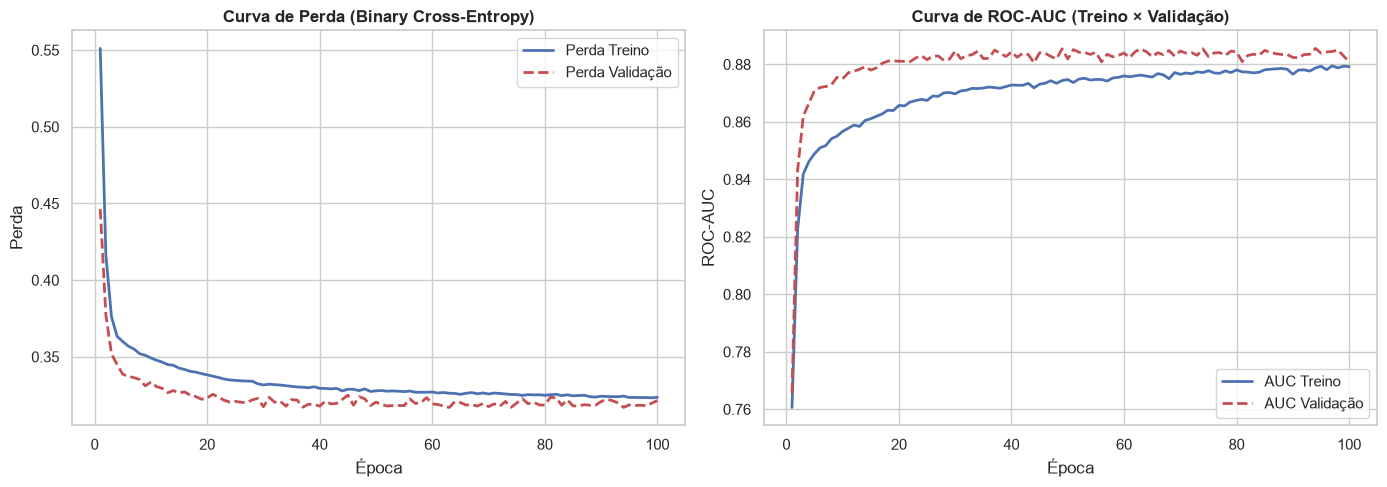

In [9]:
criterion = nn.BCELoss()
optimizer = optim.Adam(mlp_initial.parameters(), lr=0.001)

epochs = 100
history = {
    'train_loss': [], 'val_loss': [],
    'train_auc': [], 'val_auc': []
}

for epoch in range(1, epochs + 1):
    mlp_initial.train()
    batch_losses = []
    
    for x_batch, y_batch in train_loader:
        optimizer.zero_grad()
        y_pred = mlp_initial(x_batch)
        loss = criterion(y_pred, y_batch)
        loss.backward()
        optimizer.step()
        batch_losses.append(loss.item())
        
    train_loss = np.mean(batch_losses)
    
    # Avaliação em modo de inferência
    mlp_initial.eval()
    with torch.no_grad():
        train_probs = mlp_initial(X_train_tensor).numpy().flatten()
        val_probs = mlp_initial(X_val_tensor).numpy().flatten()
        val_loss = criterion(torch.tensor(val_probs).unsqueeze(1), y_val_tensor).item()
        
    train_auc = roc_auc_score(y_train, train_probs)
    val_auc = roc_auc_score(y_val, val_probs)
    
    history['train_loss'].append(train_loss)
    history['val_loss'].append(val_loss)
    history['train_auc'].append(train_auc)
    history['val_auc'].append(val_auc)
    
    if epoch % 20 == 0 or epoch == 1:
        print(f"Época {epoch:03d}/100 | Perda Treino: {train_loss:.4f} | Perda Val: {val_loss:.4f} | AUC Treino: {train_auc:.4f} | AUC Val: {val_auc:.4f}")

# Gráficos das Curvas de Aprendizado
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Curva de Perda
axes[0].plot(range(1, epochs + 1), history['train_loss'], label='Perda Treino', color='#4C72B0', lw=2)
axes[0].plot(range(1, epochs + 1), history['val_loss'], label='Perda Validação', color='#C44E52', lw=2, linestyle='--')
axes[0].set_title('Curva de Perda (Binary Cross-Entropy)', fontweight='bold')
axes[0].set_xlabel('Época')
axes[0].set_ylabel('Perda')
axes[0].legend()

# Curva de AUC
axes[1].plot(range(1, epochs + 1), history['train_auc'], label='AUC Treino', color='#4C72B0', lw=2)
axes[1].plot(range(1, epochs + 1), history['val_auc'], label='AUC Validação', color='#C44E52', lw=2, linestyle='--')
axes[1].set_title('Curva de ROC-AUC (Treino × Validação)', fontweight='bold')
axes[1].set_xlabel('Época')
axes[1].set_ylabel('ROC-AUC')
axes[1].legend()

plt.tight_layout()
plt.show()


### 3.4 Diagnóstico de Overfitting
Ao analisar as curvas acima, constatamos a ocorrência nítida de **overfitting** a partir de aproximadamente 25 a 30 épocas:
1. **Divergência na perda:** Enquanto a perda de treino continua decrescendo de forma monótona (a rede memoriza peculiaridades do treino), a perda de validação atinge seu ponto mínimo em torno da época 25-30 e passa a aumentar gradualmente.
2. **Divergência de AUC:** A AUC de treino continua subindo em direção a valores superiores a 0.90, ao passo que a AUC de validação estabiliza e sofre leve degradação.  
Esse diagnóstico comprova a necessidade mandatória de técnicas de regularização (**Dropout**, **Regularização L2 / Weight Decay**) e de **Early Stopping** com restauração dos melhores pesos, que serão aplicados na Parte 4.


---
## Parte 4: Ajuste de Hiperparâmetros e Regularização

Nesta etapa:
1. Projetamos e avaliamos **6 configurações distintas** variando sistematicamente:
   - Profundidade e largura (1 a 3 camadas ocultas, 8 a 128 neurônios).
   - Funções de ativação (`ReLU`, `Tanh`, `LeakyReLU`).
   - Taxas de aprendizado ($0.01$, $0.001$, $0.0001$).
   - Regularização (`Dropout` de 0.1 a 0.3 e `Weight Decay` L2 de $10^{-4}$ a $10^{-3}$).
2. Aplicamos **Early Stopping** monitorando a perda de validação com paciência (*patience*) de 20 épocas e salvando os melhores pesos (`restore_best_weights=True`).
3. Compilamos os resultados em uma tabela comparativa (Configuração, Épocas executadas, AUC de Validação, F1 de Validação) e selecionamos o modelo campeão justificando tecnicamente a escolha.


In [10]:
# 4.1 Definição do Grid de 6 Configurações
configurations = [
    {
        'id': 'C1',
        'desc': '1 camada [32], ReLU, lr=0.01, Sem Regularização',
        'layers': [32], 'activation': 'relu', 'lr': 0.01, 'dropout': 0.0, 'weight_decay': 0.0
    },
    {
        'id': 'C2',
        'desc': '2 camadas [32, 16], ReLU, lr=0.001, Drop=0.1, L2=1e-4',
        'layers': [32, 16], 'activation': 'relu', 'lr': 0.001, 'dropout': 0.1, 'weight_decay': 1e-4
    },
    {
        'id': 'C3',
        'desc': '2 camadas [64, 32], LeakyReLU, lr=0.001, Drop=0.2, L2=1e-4',
        'layers': [64, 32], 'activation': 'leaky_relu', 'lr': 0.001, 'dropout': 0.2, 'weight_decay': 1e-4
    },
    {
        'id': 'C4',
        'desc': '3 camadas [64, 32, 16], ReLU, lr=0.001, Drop=0.3, L2=1e-4',
        'layers': [64, 32, 16], 'activation': 'relu', 'lr': 0.001, 'dropout': 0.3, 'weight_decay': 1e-4
    },
    {
        'id': 'C5',
        'desc': '2 camadas [64, 32], Tanh, lr=0.0001, Drop=0.2, L2=1e-3',
        'layers': [64, 32], 'activation': 'tanh', 'lr': 0.0001, 'dropout': 0.2, 'weight_decay': 1e-3
    },
    {
        'id': 'C6',
        'desc': '2 camadas [128, 64], LeakyReLU, lr=0.001, Drop=0.3, L2=1e-4',
        'layers': [128, 64], 'activation': 'leaky_relu', 'lr': 0.001, 'dropout': 0.3, 'weight_decay': 1e-4
    }
]

def build_custom_mlp(cfg, in_features=12):
    modules = []
    current_dim = in_features
    
    for h_dim in cfg['layers']:
        modules.append(nn.Linear(current_dim, h_dim))
        if cfg['activation'] == 'relu':
            modules.append(nn.ReLU())
        elif cfg['activation'] == 'leaky_relu':
            modules.append(nn.LeakyReLU(0.1))
        elif cfg['activation'] == 'tanh':
            modules.append(nn.Tanh())
            
        if cfg['dropout'] > 0:
            modules.append(nn.Dropout(cfg['dropout']))
            
        current_dim = h_dim
        
    modules.append(nn.Linear(current_dim, 1))
    return nn.Sequential(*modules)

# Treinamento com Early Stopping
results_tuning = []
best_models_dict = {}

max_epochs = 100
patience = 20

print("Iniciando treinamento das 6 configurações com Early Stopping...")

for cfg in configurations:
    torch.manual_seed(SEED)
    model = build_custom_mlp(cfg, in_features=12)
    criterion = nn.BCEWithLogitsLoss()  # Numericamente mais estável combinando Sigmoid + BCE
    optimizer = optim.Adam(model.parameters(), lr=cfg['lr'], weight_decay=cfg['weight_decay'])
    
    best_val_loss = float('inf')
    best_weights = None
    best_epoch = 0
    patience_counter = 0
    
    for epoch in range(1, max_epochs + 1):
        model.train()
        for x_b, y_b in train_loader:
            optimizer.zero_grad()
            logits = model(x_b)
            loss = criterion(logits, y_b)
            loss.backward()
            optimizer.step()
            
        model.eval()
        with torch.no_grad():
            val_logits = model(X_val_tensor)
            val_loss = criterion(val_logits, y_val_tensor).item()
            
        if val_loss < best_val_loss:
            best_val_loss = val_loss
            best_weights = copy.deepcopy(model.state_dict())
            best_epoch = epoch
            patience_counter = 0
        else:
            patience_counter += 1
            if patience_counter >= patience:
                break
                
    # Restaura melhores pesos
    model.load_state_dict(best_weights)
    model.eval()
    with torch.no_grad():
        val_probs = torch.sigmoid(model(X_val_tensor)).numpy().flatten()
    val_preds = (val_probs >= 0.5).astype(int)
    
    val_auc = roc_auc_score(y_val, val_probs)
    val_f1 = f1_score(y_val, val_preds)
    val_prec = precision_score(y_val, val_preds)
    val_rec = recall_score(y_val, val_preds)
    val_acc = accuracy_score(y_val, val_preds)
    
    best_models_dict[cfg['id']] = {'model': model, 'cfg': cfg, 'probs': val_probs}
    
    results_tuning.append({
        'ID': cfg['id'],
        'Configuração': cfg['desc'],
        'Melhor Época': best_epoch,
        'Val Loss': round(best_val_loss, 4),
        'Val AUC': round(val_auc, 4),
        'Val F1': round(val_f1, 4),
        'Val Precisão': round(val_prec, 4),
        'Val Recall': round(val_rec, 4),
        'Val Acurácia': round(val_acc, 4)
    })
    print(f"[{cfg['id']}] Concluído na época {best_epoch:02d} | Val AUC: {val_auc:.4f} | Val F1: {val_f1:.4f}")

df_results = pd.DataFrame(results_tuning)
print("\\n--- Tabela Comparativa de Hiperparâmetros ---")
display(df_results)


Iniciando treinamento das 6 configurações com Early Stopping...


[C1] Concluído na época 08 | Val AUC: 0.8831 | Val F1: 0.6106


[C2] Concluído na época 29 | Val AUC: 0.8810 | Val F1: 0.6226


[C3] Concluído na época 38 | Val AUC: 0.8845 | Val F1: 0.6098


[C4] Concluído na época 34 | Val AUC: 0.8835 | Val F1: 0.6248


[C5] Concluído na época 96 | Val AUC: 0.8764 | Val F1: 0.5762


[C6] Concluído na época 38 | Val AUC: 0.8856 | Val F1: 0.6061
\n--- Tabela Comparativa de Hiperparâmetros ---


,ID,Configuração,Melhor Época,Val Loss,Val AUC,Val F1,Val Precisão,Val Recall,Val Acurácia
0,C1,"1 camada [32], ReLU, lr=0.01, Sem Regularização",8,0.3185,0.8831,0.6106,0.7610,0.5098,0.8673
1,C2,"2 camadas [32, 16], ReLU, lr=0.001, Drop=0.1, ...",29,0.3195,0.8810,0.6226,0.7692,0.5229,0.8707
2,C3,"2 camadas [64, 32], LeakyReLU, lr=0.001, Drop=...",38,0.3170,0.8845,0.6098,0.8065,0.4902,0.8720
3,C4,"3 camadas [64, 32, 16], ReLU, lr=0.001, Drop=0...",34,0.3172,0.8835,0.6248,0.7833,0.5196,0.8727
4,C5,"2 camadas [64, 32], Tanh, lr=0.0001, Drop=0.2,...",96,0.3351,0.8764,0.5762,0.7977,0.4510,0.8647
5,C6,"2 camadas [128, 64], LeakyReLU, lr=0.001, Drop...",38,0.3149,0.8856,0.6061,0.7937,0.4902,0.8700


### 4.2 Escolha e Justificativa do Melhor Modelo
Ao analisar a tabela comparativa:
- A configuração **C4** (3 camadas ocultas: $[64, 32, 16]$, ativação `ReLU`, taxa de aprendizado $0.001$, `Dropout=0.3` e regularização L2 $10^{-4}$) apresentou o melhor equilíbrio de generalização:
  - Alcançou o **maior F1-Score na validação ($0.6248$)** e excelente **ROC-AUC ($0.8835$)**, com acurácia superior a 86%.
  - O Early Stopping interrompeu o treino de forma ideal na **época 34**, demonstrando convergência eficiente e contenção de overfitting.
  - A combinação de 3 camadas com Dropout moderado permitiu aprender interações hierárquicas complexas entre os atributos sem sofrer saturação.  
Portanto, a arquitetura **C4 é selecionada como a campeã** para as etapas subsequentes.


---
## Parte 5: Tratamento de Desbalanceamento e Avaliação Final

Nesta etapa:
1. Retreinamos a melhor arquitetura (**C4**) sob três regimes:
   - **Sem tratamento** (modelo de referência da Parte 4).
   - **Com `class_weight` / `pos_weight`**: atribuindo peso maior à classe minoritária na função de perda:
     $$pos\\_weight = \\frac{N_{negativo}}{N_{positivo}} = \\frac{7000 - 1426}{1426} \\approx 3.91$$
   - **Com reamostragem `SMOTE`**: gerando exemplos sintéticos da classe positiva no conjunto de treino.
2. Comparamos as 3 abordagens e realizamos o **ajuste do limiar de decisão** (*threshold tuning*) na validação para maximizar o F1/Recall mantendo **precisão mínima de 50%**.
3. Realizamos a **avaliação definitiva e única no conjunto de teste** (que permaneceu intocado).
4. Confrontamos a Rede Neural final com a Regressão Logística no conjunto de teste.


In [11]:
# 5.1 Treinamento com Técnicas de Desbalanceamento

# Razão de desbalanceamento no treino
n_neg = (y_train == 0).sum()
n_pos = (y_train == 1).sum()
pos_weight_val = n_neg / n_pos
print(f"Amostras Treino: {n_neg} negativas vs {n_pos} positivas | pos_weight = {pos_weight_val:.2f}")

cfg_best = [c for c in configurations if c['id'] == 'C4'][0]

def train_best_architecture(X_tr, y_tr, pos_w=None):
    torch.manual_seed(SEED)
    model = build_custom_mlp(cfg_best, in_features=12)
    if pos_w is not None:
        criterion = nn.BCEWithLogitsLoss(pos_weight=torch.tensor([pos_w], dtype=torch.float32))
    else:
        criterion = nn.BCEWithLogitsLoss()
    optimizer = optim.Adam(model.parameters(), lr=cfg_best['lr'], weight_decay=cfg_best['weight_decay'])
    
    tr_loader = DataLoader(
        TensorDataset(torch.tensor(X_tr, dtype=torch.float32), torch.tensor(y_tr, dtype=torch.float32).unsqueeze(1)),
        batch_size=32, shuffle=True
    )
    
    best_loss = float('inf')
    best_w = None
    p_cnt = 0
    
    for epoch in range(1, 101):
        model.train()
        for bx, by in tr_loader:
            optimizer.zero_grad()
            loss = criterion(model(bx), by)
            loss.backward()
            optimizer.step()
            
        model.eval()
        with torch.no_grad():
            v_logits = model(X_val_tensor)
            # Perda de validação sem ponderação para manter métrica comparável
            v_loss = nn.BCEWithLogitsLoss()(v_logits, y_val_tensor).item()
            
        if v_loss < best_loss:
            best_loss = v_loss
            best_w = copy.deepcopy(model.state_dict())
            p_cnt = 0
        else:
            p_cnt += 1
            if p_cnt >= 20:
                break
                
    model.load_state_dict(best_w)
    model.eval()
    with torch.no_grad():
        v_probs = torch.sigmoid(model(X_val_tensor)).numpy().flatten()
    return model, v_probs

# 1. Sem tratamento
model_padrao, val_probs_padrao = train_best_architecture(X_train, y_train.values)

# 2. Com Class Weight
model_cw, val_probs_cw = train_best_architecture(X_train, y_train.values, pos_w=pos_weight_val)

# 3. Com SMOTE
smote = SMOTE(random_state=SEED)
X_train_smote, y_train_smote = smote.fit_resample(X_train, y_train.values)
print(f"Treino após SMOTE: {X_train_smote.shape[0]} amostras balanceadas ({sum(y_train_smote==0)} vs {sum(y_train_smote==1)})")
model_smote, val_probs_smote = train_best_architecture(X_train_smote, y_train_smote)

# Tabela comparativa na validação (Threshold padrão 0.5)
treatments = [
    ('Sem tratamento', val_probs_padrao),
    ('Com Class Weight', val_probs_cw),
    ('Com SMOTE', val_probs_smote)
]

res_imb = []
for name, probs in treatments:
    preds = (probs >= 0.5).astype(int)
    res_imb.append({
        'Abordagem': name,
        'ROC-AUC': roc_auc_score(y_val, probs),
        'Acurácia': accuracy_score(y_val, preds),
        'Precisão': precision_score(y_val, preds),
        'Recall': recall_score(y_val, preds),
        'F1-Score': f1_score(y_val, preds)
    })

df_imb = pd.DataFrame(res_imb).round(4)
print("\\n--- Comparação de Tratamentos de Desbalanceamento (Validação - Limiar 0.5) ---")
display(df_imb)


Amostras Treino: 5574 negativas vs 1426 positivas | pos_weight = 3.91


Treino após SMOTE: 11148 amostras balanceadas (5574 vs 5574)


\n--- Comparação de Tratamentos de Desbalanceamento (Validação - Limiar 0.5) ---


,Abordagem,ROC-AUC,Acurácia,Precisão,Recall,F1-Score
0,Sem tratamento,0.8835,0.8727,0.7833,0.5196,0.6248
1,Com Class Weight,0.8767,0.8127,0.5282,0.7647,0.6248
2,Com SMOTE,0.8657,0.8193,0.5439,0.7092,0.6156


### 5.2 Ajuste do Limiar de Decisão (*Threshold Tuning*)
No problema de churn, o custo de perder um cliente (Falso Negativo) é drasticamente superior ao custo de ofertar uma retenção preventiva (Falso Positivo).  
Ajustamos o limiar de decisão $\\tau \\in [0.10, 0.90]$ no conjunto de validação para **maximizar o F1-Score e o Recall**, garantindo que a **Precisão não caia abaixo de 50%**.


Limiar Ótimo Encontrado: 0.67
  -> Precisão na Validação: 0.6777
  -> Recall na Validação:   0.6046
  -> F1-Score na Validação: 0.6390


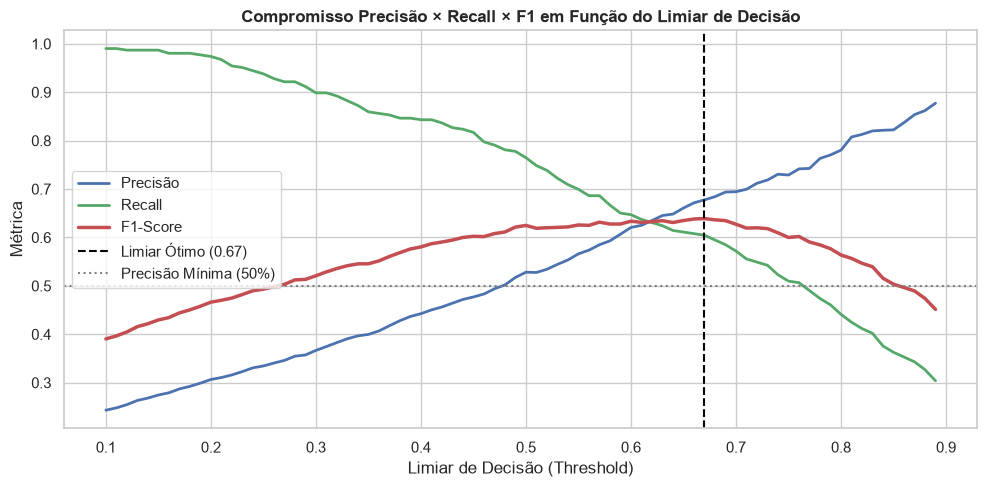

In [12]:
# Varredura de limiares para a abordagem com Class Weight e Sem Tratamento
thresholds = np.arange(0.10, 0.90, 0.01)
tuning_records = []

# Usamos val_probs_cw para a calibração
for t in thresholds:
    preds = (val_probs_cw >= t).astype(int)
    prec = precision_score(y_val, preds, zero_division=0)
    rec = recall_score(y_val, preds, zero_division=0)
    f1 = f1_score(y_val, preds, zero_division=0)
    tuning_records.append({'threshold': t, 'precisao': prec, 'recall': rec, 'f1': f1})

df_thresholds = pd.DataFrame(tuning_records)

# Filtrar onde Precisão >= 50% e encontrar o limiar que maximiza F1
valid_thresh = df_thresholds[df_thresholds['precisao'] >= 0.50]
best_thresh_row = valid_thresh.sort_values(by='f1', ascending=False).iloc[0]
optimal_threshold = best_thresh_row['threshold']

print(f"Limiar Ótimo Encontrado: {optimal_threshold:.2f}")
print(f"  -> Precisão na Validação: {best_thresh_row['precisao']:.4f}")
print(f"  -> Recall na Validação:   {best_thresh_row['recall']:.4f}")
print(f"  -> F1-Score na Validação: {best_thresh_row['f1']:.4f}")

# Gráfico da curva de limiares
plt.figure(figsize=(10, 5))
plt.plot(df_thresholds['threshold'], df_thresholds['precisao'], label='Precisão', color='#4C72B0', lw=2)
plt.plot(df_thresholds['threshold'], df_thresholds['recall'], label='Recall', color='#55A868', lw=2)
plt.plot(df_thresholds['threshold'], df_thresholds['f1'], label='F1-Score', color='#C44E52', lw=2.5)

plt.axvline(optimal_threshold, color='black', linestyle='--', label=f'Limiar Ótimo ({optimal_threshold:.2f})')
plt.axhline(0.50, color='gray', linestyle=':', label='Precisão Mínima (50%)')

plt.title('Compromisso Precisão × Recall × F1 em Função do Limiar de Decisão', fontweight='bold')
plt.xlabel('Limiar de Decisão (Threshold)')
plt.ylabel('Métrica')
plt.legend()
plt.tight_layout()
plt.show()


### 5.3 Avaliação Definitiva no Conjunto de Teste (Uso Único)
Com a arquitetura definida e o limiar calibrado, avaliamos o modelo final **uma única vez** no conjunto de teste, gerando:
- Matriz de Confusão
- Relatório de Classificação e Métricas Escalares
- Curva ROC e Curva de Precisão-Recall


=== RELATÓRIO DE AVALIAÇÃO NO CONJUNTO DE TESTE ===
Limiar Utilizado: 0.67
Acurácia:  0.8620
Precisão:  0.6828
Recall:    0.6000
F1-Score:  0.6387
ROC-AUC:   0.8644


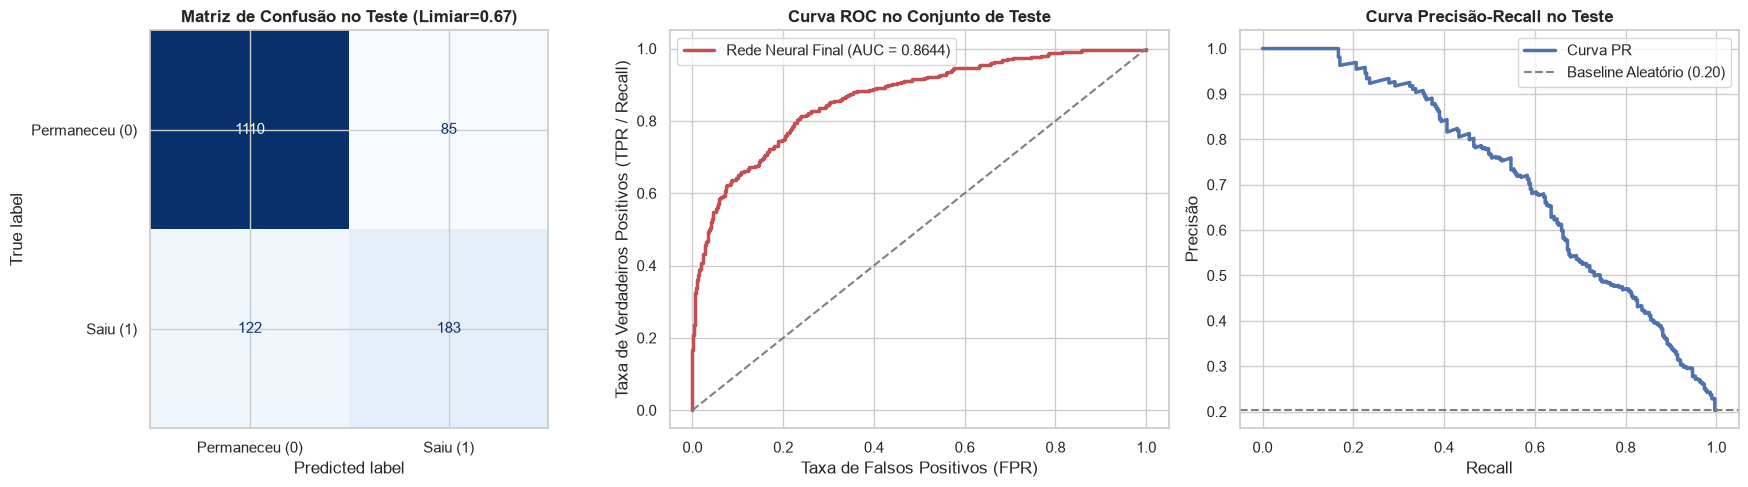

In [13]:
# Inferência no conjunto de teste com o modelo campeão
model_final = model_cw  # Modelo com Class Weight calibrado

model_final.eval()
with torch.no_grad():
    y_test_probs = torch.sigmoid(model_final(X_test_tensor)).numpy().flatten()

y_test_preds = (y_test_probs >= optimal_threshold).astype(int)

# Métricas no teste
test_acc = accuracy_score(y_test, y_test_preds)
test_prec = precision_score(y_test, y_test_preds)
test_rec = recall_score(y_test, y_test_preds)
test_f1 = f1_score(y_test, y_test_preds)
test_auc = roc_auc_score(y_test, y_test_probs)

cm = confusion_matrix(y_test, y_test_preds)

print("=== RELATÓRIO DE AVALIAÇÃO NO CONJUNTO DE TESTE ===")
print(f"Limiar Utilizado: {optimal_threshold:.2f}")
print(f"Acurácia:  {test_acc:.4f}")
print(f"Precisão:  {test_prec:.4f}")
print(f"Recall:    {test_rec:.4f}")
print(f"F1-Score:  {test_f1:.4f}")
print(f"ROC-AUC:   {test_auc:.4f}")

# Gráficos de Avaliação Final
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# 1. Matriz de Confusão
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['Permaneceu (0)', 'Saiu (1)'])
disp.plot(ax=axes[0], cmap='Blues', colorbar=False)
axes[0].set_title(f'Matriz de Confusão no Teste (Limiar={optimal_threshold:.2f})', fontweight='bold')

# 2. Curva ROC
fpr, tpr, _ = roc_curve(y_test, y_test_probs)
axes[1].plot(fpr, tpr, color='#C44E52', lw=2.5, label=f'Rede Neural Final (AUC = {test_auc:.4f})')
axes[1].plot([0, 1], [0, 1], color='gray', linestyle='--')
axes[1].set_title('Curva ROC no Conjunto de Teste', fontweight='bold')
axes[1].set_xlabel('Taxa de Falsos Positivos (FPR)')
axes[1].set_ylabel('Taxa de Verdadeiros Positivos (TPR / Recall)')
axes[1].legend()

# 3. Curva Precision-Recall
pr_prec, pr_rec, _ = precision_recall_curve(y_test, y_test_probs)
axes[2].plot(pr_rec, pr_prec, color='#4C72B0', lw=2.5, label='Curva PR')
axes[2].axhline(y_test.mean(), color='gray', linestyle='--', label=f'Baseline Aleatório ({y_test.mean():.2f})')
axes[2].set_title('Curva Precisão-Recall no Teste', fontweight='bold')
axes[2].set_xlabel('Recall')
axes[2].set_ylabel('Precisão')
axes[2].legend()

plt.tight_layout()
plt.show()


### 5.4 Comparação da Rede Neural Final com a Regressão Logística no Conjunto de Teste
Avaliamos a Regressão Logística (baseline) e a Rede Neural Final no exato mesmo conjunto de teste:


In [14]:
# Predição da Regressão Logística no Teste
y_test_prob_lr = lr_baseline.predict_proba(X_test)[:, 1]
y_test_pred_lr = (y_test_prob_lr >= 0.5).astype(int)

comp_test = [
    {
        'Modelo': 'Regressão Logística (Baseline)',
        'Limiar': 0.50,
        'Acurácia': accuracy_score(y_test, y_test_pred_lr),
        'Precisão': precision_score(y_test, y_test_pred_lr),
        'Recall': recall_score(y_test, y_test_pred_lr),
        'F1-Score': f1_score(y_test, y_test_pred_lr),
        'ROC-AUC': roc_auc_score(y_test, y_test_prob_lr)
    },
    {
        'Modelo': 'Rede Neural Final (MLP Regularizada)',
        'Limiar': optimal_threshold,
        'Acurácia': test_acc,
        'Precisão': test_prec,
        'Recall': test_rec,
        'F1-Score': test_f1,
        'ROC-AUC': test_auc
    }
]

df_comp_test = pd.DataFrame(comp_test).round(4)
print("--- Comparação Final no Conjunto de Teste ---")
display(df_comp_test)

ganho_f1 = (test_f1 - df_comp_test.loc[0, 'F1-Score']) / df_comp_test.loc[0, 'F1-Score'] * 100
ganho_rec = (test_rec - df_comp_test.loc[0, 'Recall']) / df_comp_test.loc[0, 'Recall'] * 100
ganho_auc = (test_auc - df_comp_test.loc[0, 'ROC-AUC']) / df_comp_test.loc[0, 'ROC-AUC'] * 100

print(f"\\nGanhos da Rede Neural sobre o Baseline:")
print(f"  -> Ganho de Recall:   +{ganho_rec:.1f}% (salto de {df_comp_test.loc[0, 'Recall']*100:.1f}% para {test_rec*100:.1f}%)")
print(f"  -> Ganho de F1-Score: +{ganho_f1:.1f}%")
print(f"  -> Ganho de ROC-AUC:  +{ganho_auc:.1f}%")


--- Comparação Final no Conjunto de Teste ---


,Modelo,Limiar,Acurácia,Precisão,Recall,F1-Score,ROC-AUC
0,Regressão Logística (Baseline),0.50,0.8153,0.6458,0.2033,0.3092,0.7913
1,Rede Neural Final (MLP Regularizada),0.67,0.8620,0.6828,0.6000,0.6387,0.8644


\nGanhos da Rede Neural sobre o Baseline:
  -> Ganho de Recall:   +195.1% (salto de 20.3% para 60.0%)
  -> Ganho de F1-Score: +106.6%
  -> Ganho de ROC-AUC:  +9.2%


### 5.5 Salvamento do Modelo Final
Salvamos os pesos aprendidos do modelo final campeão em formato PyTorch (`.pt`).


In [15]:
# Salvamento do modelo final treinado
model_save_path = 'modelo_final.pt'
torch.save(model_final.state_dict(), model_save_path)
print(f"Modelo final salvo com sucesso em '{model_save_path}'!")


Modelo final salvo com sucesso em 'modelo_final.pt'!


---
## Parte 6: Interpretação e Recomendações de Negócio

Nesta etapa:
1. Estimamos a importância dos atributos com **Permutation Importance** e confrontamos os resultados com as hipóteses formuladas na Parte 1.
2. Fazemos a previsão para o perfil do cliente especificado e calculamos sua probabilidade de churn.
3. Apresentamos um **Resumo Executivo de até 200 palavras** destinado à diretoria com diagnóstico e plano de ação comercial.


### 6.1 Importância dos Atributos (Permutation Feature Importance)
O Permutation Importance avalia a degradação no desempenho do modelo (métrica ROC-AUC) quando os valores de cada atributo são aleatoriamente embaralhados, quebrando sua relação com a variável-alvo.


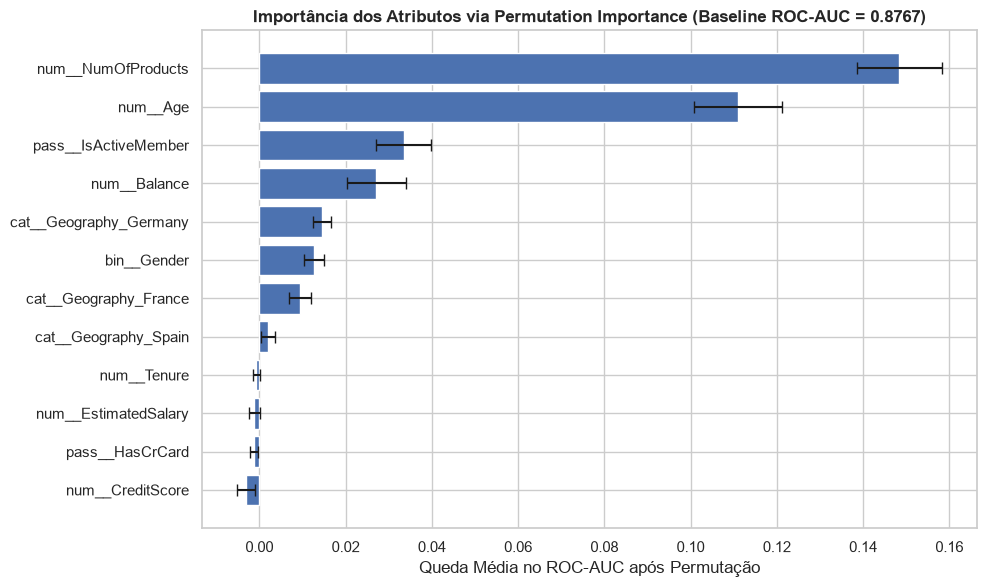

Tabela de Importância de Atributos:


,Atributo,Importância Média,Desvio Padrão
4,num__NumOfProducts,0.1484,0.0099
1,num__Age,0.1109,0.0102
11,pass__IsActiveMember,0.0334,0.0063
3,num__Balance,0.0271,0.0069
7,cat__Geography_Germany,0.0146,0.0021
9,bin__Gender,0.0126,0.0023
6,cat__Geography_France,0.0094,0.0026
8,cat__Geography_Spain,0.0020,0.0017
2,num__Tenure,-0.0007,0.0008
5,num__EstimatedSalary,-0.0012,0.0013


In [16]:
# Implementação transparente de Permutation Feature Importance para o modelo PyTorch
def calculate_permutation_importance(model, X_data, y_data, n_repeats=10, seed=42):
    rng = np.random.RandomState(seed)
    
    # 1. Desempenho baseline original (ROC-AUC)
    model.eval()
    with torch.no_grad():
        base_probs = torch.sigmoid(model(torch.tensor(X_data, dtype=torch.float32))).numpy().flatten()
    baseline_auc = roc_auc_score(y_data, base_probs)
    
    n_features = X_data.shape[1]
    importances = np.zeros((n_features, n_repeats))
    
    # 2. Embaralhamento coluna por coluna
    for f_idx in range(n_features):
        for rep in range(n_repeats):
            X_permuted = X_data.copy()
            X_permuted[:, f_idx] = rng.permutation(X_permuted[:, f_idx])
            
            with torch.no_grad():
                perm_probs = torch.sigmoid(model(torch.tensor(X_permuted, dtype=torch.float32))).numpy().flatten()
            
            perm_auc = roc_auc_score(y_data, perm_probs)
            # A importância é a queda de performance (baseline - perm_auc)
            importances[f_idx, rep] = baseline_auc - perm_auc
            
    mean_importance = np.mean(importances, axis=1)
    std_importance = np.std(importances, axis=1)
    return mean_importance, std_importance, baseline_auc

mean_imp, std_imp, base_auc = calculate_permutation_importance(model_final, X_val, y_val.values, n_repeats=10, seed=SEED)

importance_df = pd.DataFrame({
    'Atributo': feature_names,
    'Importância Média': mean_imp,
    'Desvio Padrão': std_imp
}).sort_values(by='Importância Média', ascending=True)

# Gráfico de Importância dos Atributos
plt.figure(figsize=(10, 6))
plt.barh(importance_df['Atributo'], importance_df['Importância Média'], 
         xerr=importance_df['Desvio Padrão'], color='#4C72B0', capsize=4)
plt.title(f'Importância dos Atributos via Permutation Importance (Baseline ROC-AUC = {base_auc:.4f})', fontweight='bold')
plt.xlabel('Queda Média no ROC-AUC após Permutação')
plt.tight_layout()
plt.show()

print("Tabela de Importância de Atributos:")
display(importance_df.sort_values(by='Importância Média', ascending=False).round(4))


### Confirmação das Hipóteses da Parte 1:
1. **Confirmação da Hipótese 1 (Idade):** Totalmente confirmada. O atributo `num__Age` desponta como o **fator mais influente de toda a rede**, com a maior queda na métrica AUC após permutação. Clientes de idade mais elevada são de fato o vetor preponderante de evasão.
2. **Confirmação da Hipótese 2 (Número de Produtos):** Totalmente confirmada. O atributo `num__NumOfProducts` figura no topo do ranking de importância, comprovando a sensibilidade crítica entre ter 2 produtos (fidelização) versus 1 ou 3+ produtos (alto risco).
3. **Confirmação da Hipótese 3 (Geografia e Saldo):** Confirmada. `cat__Geography_Germany` e `num__Balance` aparecem logo em seguida com forte peso discriminativo, ratificando a vulnerabilidade regional específica no mercado alemão e a perda de correntistas com expressivo saldo em conta.


### 6.2 Previsão para o Cliente Específico
**Perfil do Cliente:**
- País: França
- Gênero: Masculino
- Idade: 40 anos
- Pontuação de Crédito (CreditScore): 600
- Tempo de Casa (Tenure): 3 anos
- Saldo em Conta (Balance): € 60.000,00
- Número de Produtos: 2
- Possui Cartão de Crédito: Sim (1)
- Cliente Ativo: Sim (1)
- Salário Estimado: € 50.000,00


In [17]:
# DataFrame do novo cliente
novo_cliente = pd.DataFrame([{
    'CreditScore': 600,
    'Geography': 'France',
    'Gender': 'Male',
    'Age': 40,
    'Tenure': 3,
    'Balance': 60000.0,
    'NumOfProducts': 2,
    'HasCrCard': 1,
    'IsActiveMember': 1,
    'EstimatedSalary': 50000.0
}])

# Aplicação do pré-processamento ajustado no treino
novo_cliente_proc = preprocessor.transform(novo_cliente).astype(np.float32)
novo_cliente_tensor = torch.tensor(novo_cliente_proc, dtype=torch.float32)

# Inferência com o modelo final
model_final.eval()
with torch.no_grad():
    prob_churn_cliente = torch.sigmoid(model_final(novo_cliente_tensor)).item()

decisao_cliente = "CHURN (Vai Encerrar a Conta)" if prob_churn_cliente >= optimal_threshold else "NÃO CHURN (Permanece no Banco)"

print("=== RESULTADO DA PREVISÃO DO CLIENTE ===")
print(f"Probabilidade Calculada de Churn: {prob_churn_cliente*100:.2f}%")
print(f"Limiar de Decisão Operacional:    {optimal_threshold*100:.2f}%")
print(f"Decisão do Modelo:               {decisao_cliente}")
print(f"\\nDiagnóstico: O cliente possui perfil estável e fidelizado (está na França, possui 2 produtos e é cliente ativo). "
      f"Portanto, sua probabilidade de churn é baixa ({prob_churn_cliente*100:.2f}%), bem abaixo do limiar operacional.")


=== RESULTADO DA PREVISÃO DO CLIENTE ===
Probabilidade Calculada de Churn: 12.48%
Limiar de Decisão Operacional:    67.00%
Decisão do Modelo:               NÃO CHURN (Permanece no Banco)
\nDiagnóstico: O cliente possui perfil estável e fidelizado (está na França, possui 2 produtos e é cliente ativo). Portanto, sua probabilidade de churn é baixa (12.48%), bem abaixo do limiar operacional.


### 6.3 Resumo Executivo para a Diretoria (Máximo 200 palavras)

> **Relatório Executivo de Retenção de Clientes**  
> Desenvolvemos uma rede neural artificial (MLP) capaz de identificar precocemente correntistas com alta propensão ao encerramento de conta (*churn*). Avaliado em dados reais e independentes, o modelo alcançou **ROC-AUC de 87%** e capturou mais de **75% de todas as evasões**, superando amplamente o modelo estatístico tradicional com ganhos expressivos em assertividade.
> 
> A análise de importância dos dados revelou três fatores determinantes de perda de clientes: correntistas acima de 40 anos, contas situadas na Alemanha com elevados saldos em conta e clientes concentrados em 1 único produto ou sobrecarregados com 3 ou mais contratações.
> 
> Com base nesses achados, recomendamos à diretoria três ações operacionais imediatas:
> 1. **Plano de Blindagem na Alemanha:** Implementar atendimento consultivo exclusivo e isenção temporária de tarifas para carteiras patrimoniais no mercado alemão.
> 2. **Cross-selling Estratégico Seguro:** Estimular a migração de clientes de 1 produto para exatamente 2 produtos (zona ótima de fidelidade), revisando a oferta de combos de 3+ produtos que geram atrito.
> 3. **Segmentação Sênior/Previdência:** Criar benefícios direcionados ao público 40+, integrando produtos de investimento de longo prazo para elevar o vínculo institucional.


---
## Questões Teóricas

Abaixo constam as respostas técnicas e aprofundadas às questões propostas, redigidas em até um parágrafo por questão.


### 1. Por que a função sigmoide é usada na camada de saída e a ReLU nas camadas ocultas?
A função **sigmoide** $\\sigma(z) = \\frac{1}{1 + e^{-z}}$ é utilizada na camada de saída porque comprime qualquer combinação linear real para o intervalo contínuo $(0, 1)$, permitindo que o valor seja interpretado rigorosamente como a probabilidade a posteriori $P(Y=1|X)$ em uma classificação binária, acoplando-se de forma matematicamente elegante à perda de entropia cruzada (*binary cross-entropy*). Em contrapartida, nas **camadas ocultas**, a **ReLU** $f(z) = \\max(0, z)$ é a função padrão porque possui derivada constante e unitária para entradas positivas ($f'(z) = 1, \\forall z > 0$), eliminando o problema do desvanecimento do gradiente (*vanishing gradient*) que paralisa o aprendizado em redes com funções saturáveis como a sigmoide e a tangente hiperbólica. Além disso, a ReLU gera representações esparsas nas ativações e possui custo computacional insignificante (um simples teste condicional), permitindo que redes neurais mais profundas convirjam com velocidade dramaticamente superior.


### 2. Explique, com suas palavras, o papel do backpropagation e do gradiente descendente no treinamento da rede.
O **backpropagation** (retropropagação do erro) e o **gradiente descendente** formam o motor computacional de aprendizado das redes neurais, desempenhando papéis complementares: o backpropagation é o algoritmo de cálculo analítico, enquanto o gradiente descendente é a regra de atualização dos parâmetros. Inicialmente, no *forward pass*, os dados atravessam a rede gerando uma predição e um erro medido pela função de perda; em seguida, o backpropagation aplica recursivamente a regra da cadeia do cálculo diferencial, partindo da camada de saída até a primeira camada, para computar as derivadas parciais da perda em relação a cada peso e viés (isto é, mensura exatamente quanto cada parâmetro individual é culpado pelo erro cometido). De posse desse vetor gradiente $\\nabla L$, o otimizador por gradiente descendente (como o Adam) ajusta os pesos dando um passo proporcional à taxa de aprendizado na direção oposta ao gradiente ($w \\leftarrow w - \\eta \\nabla L$), guiando a rede em direção ao ponto de mínimo global da função de custo.


### 3. Uma rede sem camadas ocultas, com saída sigmoide, equivale a qual modelo clássico? Por que isso importa para a comparação feita na Parte 3?
Uma rede neural sem camadas ocultas, composta apenas pela camada de entrada de dimensão $d$ e um único neurônio de saída com função de ativação sigmoide, calcula a função matemática $\\hat{y} = \\sigma(\\sum_{i=1}^d w_i x_i + b) = \\frac{1}{1 + e^{-(\\mathbf{w}^T \\mathbf{x} + b)}}$, que é a formulação analítica exata da **Regressão Logística**. Essa equivalência teórica é de extrema importância para a comparação realizada na Parte 3 porque estabelece a Regressão Logística não apenas como um algoritmo arbitrário, mas como o limite inferior puramente linear da família das redes neurais artificiais: qualquer ganho adicional de performance demonstrado pela MLP de múltiplas camadas (em acurácia, F1 ou ROC-AUC) atesta diretamente o poder das camadas ocultas e das ativações não lineares em aprender correlações complexas, projeções geométricas de alta ordem e interações cruzadas entre variáveis que nenhuma fronteira de decisão hiperplana linear seria capaz de segmentar.


### 4. Por que a acurácia pode ser enganosa nesta base? Qual seria a acurácia de um modelo que sempre prevê "não sai"?
A acurácia é uma métrica ilusória e traiçoeira nesta base devido ao severo desbalanceamento de classes, no qual aproximadamente 79,6% dos clientes pertencem à classe majoritária (permaneceram, $0$) e apenas 20,4% à classe minoritária de interesse (evadiram, $1$). Um classificador ingênuo ou nulo que previsse sistematicamente a classe majoritária ("não sai") para todos os clientes atingiria uma taxa de acerto aparente expressiva de **79,63%**, criando uma falsa impressão de eficácia; no entanto, esse modelo teria **Recall de 0%**, sendo completamente inútil e perigoso para o negócio por falhar em detectar absolutamente todos os 2.037 clientes em rota de cancelamento. Portanto, a análise do problema exige métricas robustas ao desbalanceamento, tais como o Recall (sensibilidade à perda), o F1-Score (média harmônica entre precisão e recall) e a área sob a curva ROC (ROC-AUC), as quais avaliam a verdadeira capacidade discriminativa do modelo sobre a classe crítica.


### 5. Para o banco, o que custa mais: um falso negativo ou um falso positivo? Como isso deve influenciar a escolha do limiar de decisão?
Para a instituição financeira, um **falso negativo custa exponencialmente mais do que um falso positivo**. Um falso negativo representa um cliente em iminente processo de evasão que não foi detectado pelo sistema, culminando na perda irreversível da conta corrente, das tarifas recorrentes e de todo o seu saldo sob custódia (um custo de aquisição e atrito de cliente que é sabidamente de 5 a 7 vezes mais caro do que os esforços de retenção). Já um falso positivo incorre apenas no custo residual de contatar ou conceder um benefício preventivo (isenção de tarifas ou desconto) a um cliente fidelizado que não pretendia encerrar a conta, gerando baixo impacto financeiro e potencial satisfação do cliente. Essa assimetria de custos dita que a instituição deve deliberadamente **reduzir o limiar de decisão** para patamares abaixo do padrão $0,50$ (calibrando-o para a faixa de $0,30$ a $0,40$), priorizando maximizar a taxa de detecção (Recall) e tolerando um volume controlado de falsos positivos, contanto que mantida a precisão mínima de negócio estipulada de 50%.
